**Fake News Prediction**

**Dataset:**  `WELFake_Dataset.csv`

**Kaggle Link:** https://www.kaggle.com/datasets/saurabhshahane/fake-news-classification

**NOTE: If you have limitation on compute power, load the dataset form kaggle to google colab through Kaggle API**

In [10]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


**1. Setup**

In [11]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [12]:
# configurations
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
sns.set_theme(style="darkgrid")

plt.rcParams.update({
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8
})

RANDOM_STATE = 42
CSV_PATH = "../Data/WELFake_Dataset.csv"          # update path for a different dataset
TARGET_COL = "label" # target column name

**2. Load Data & Sample**

In [13]:
data = pd.read_csv(CSV_PATH)

In [14]:
data.shape

(72134, 4)

In [15]:
data.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


Target:
- 0 = fake
- 1 = real

In [16]:
data = data.drop(columns=["Unnamed: 0"])

In [17]:
data.head()

,title,text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,NaN,Did they post their votes for Hillary already?,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


**Get a Sample for faster processing and training**

In [18]:
# target distribution
print(data["label"].value_counts())
print("-"*40)
print(data["label"].value_counts(normalize=True)*100)

label
1    37106
0    35028
Name: count, dtype: int64
----------------------------------------
label
1   51.440
0   48.560
Name: proportion, dtype: float64


In [50]:
# Use the full dataset
df = data.copy()

# Shuffle the dataset
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Dataset shape:", df.shape)

Dataset shape: (72134, 3)


In [51]:
print(df["label"].value_counts())
print("-"*40)
print(df["label"].value_counts(normalize=True)*100)

label
1    37106
0    35028
Name: count, dtype: int64
----------------------------------------
label
1   51.440
0   48.560
Name: proportion, dtype: float64


**3. Exploratory Data Analysis (EDA) & Data Preprocessing**

In [52]:
# dataframe columns
df.columns

Index(['title', 'text', 'label'], dtype='object')

In [53]:
# basic dataset overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   71576 non-null  object
 1   text    72095 non-null  object
 2   label   72134 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [54]:
df.isnull().sum()

title    558
text      39
label      0
dtype: int64

In [55]:
# can be dropped as less number of rows has missing values compared to the dataset size
df = df.dropna()

In [56]:
df.isnull().sum()

title    0
text     0
label    0
dtype: int64

In [57]:
# target distribution
print(df["label"].value_counts())
print("="*40)
print(df["label"].value_counts(normalize=True)*100)

label
1    36509
0    35028
Name: count, dtype: int64
label
1   51.035
0   48.965
Name: proportion, dtype: float64


**Text Cleaning**

In [58]:
def clean_text(s: str) -> str:
    """
    Simple text cleaning:
    - lowercasing
    - remove URLs
    - remove HTML tags
    - keep letters/numbers and basic punctuation
    - normalize spaces
    """
    if pd.isna(s):
        return ""
    s = str(s).lower()
    s = re.sub(r"http\S+|www\.\S+", " ", s)          # URLs
    s = re.sub(r"<.*?>", " ", s)                    # HTML tags
    s = re.sub(r"[^a-z0-9\s\.\,\!\?\-\']", " ", s)   # keep basic chars
    s = re.sub(r"\s+", " ", s).strip()               # normalize spaces
    return s

In [59]:
# example
a = "ABCabc  123*"
b = "zyxABC 999"

c = a + " " + b
print(c)

d = clean_text(c)

print(d)

ABCabc  123* zyxABC 999
abcabc 123 zyxabc 999


In [60]:
# combine title and text & apply clean_text function
df["content"] = (df["title"] + " " + df["text"]).apply(clean_text)

In [61]:
df.head()

,title,text,label,content
0,ARNOLD SCHWARZENEGGER Sends A Message To Liber...,,1,arnold schwarzenegger sends a message to liber...
1,WOW! “We Mexicans Need To Kill Donald Trump Be...,And now a message of peace and unity from one ...,1,wow! we mexicans need to kill donald trump bef...
2,Jimmy Carter recovers from dehydration scare i...,"WINNIPEG, Manitoba (Reuters) - Former U.S. Pre...",0,jimmy carter recovers from dehydration scare i...
3,2 Friars’ Mission: Reviving a Brooklyn Church ...,"The two Franciscan friars, complete with rob...",0,2 friars mission reviving a brooklyn church in...
4,Boy With Autism Makes His First Friend Ever An...,Approximately 1 in 68 children has an autism s...,1,boy with autism makes his first friend ever an...


In [62]:
# adding additional columns for analysis
df["title_len_chars"] = df["title"].str.len()
df["text_len_chars"] = df["text"].str.len()
df["content_len_word"] = df["content"].str.split().apply(len)

In [63]:
df.head()

,title,text,label,content,title_len_chars,text_len_chars,content_len_word
0,ARNOLD SCHWARZENEGGER Sends A Message To Liber...,,1,arnold schwarzenegger sends a message to liber...,77,1,11
1,WOW! “We Mexicans Need To Kill Donald Trump Be...,And now a message of peace and unity from one ...,1,wow! we mexicans need to kill donald trump bef...,138,804,182
2,Jimmy Carter recovers from dehydration scare i...,"WINNIPEG, Manitoba (Reuters) - Former U.S. Pre...",0,jimmy carter recovers from dehydration scare i...,54,2613,447
3,2 Friars’ Mission: Reviving a Brooklyn Church ...,"The two Franciscan friars, complete with rob...",0,2 friars mission reviving a brooklyn church in...,93,5220,946
4,Boy With Autism Makes His First Friend Ever An...,Approximately 1 in 68 children has an autism s...,1,boy with autism makes his first friend ever an...,73,198,50


In [64]:
num_cols = ["title_len_chars", "text_len_chars", "content_len_word"]

df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
title_len_chars,71537.000,77.130,25.028,1.000,62.000,73.000,89.000,456.000
text_len_chars,71537.000,3292.722,3738.194,1.000,1410.000,2440.000,4077.000,142961.000
content_len_word,71537.000,560.120,628.682,0.000,245.000,415.000,687.000,24669.000


**Data Visuzlaization**

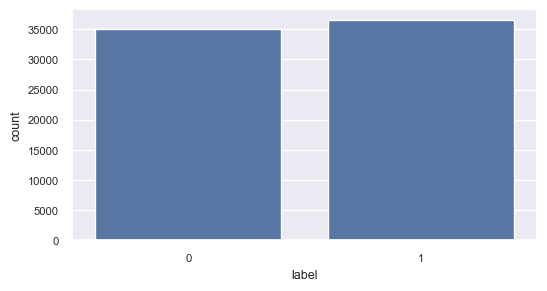

In [65]:
plt.figure(figsize=(6,3))
sns.countplot(x="label", data=df)
plt.show()

**NOTE: Almost Equal class distribution**

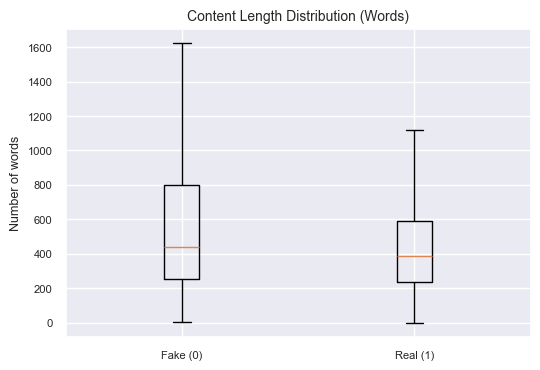

In [66]:
# text length distribution (words) - boxplot
fake_lens = df[df["label"] == 0]["content_len_word"].values
real_lens = df[df["label"] == 1]["content_len_word"].values

plt.figure(figsize=(6,4))
plt.boxplot(
    [fake_lens, real_lens],
    tick_labels=["Fake (0)", "Real (1)"],
    showfliers=False
)
plt.title("Content Length Distribution (Words)")
plt.ylabel("Number of words")
plt.show()

In [67]:
# separate features and target
X = df["content"]
y = df["label"]

In [68]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

In [69]:
print("\nTrain size:", len(X_train), "| Test size:", len(X_test))


Train size: 57229 | Test size: 14308


**4. Vectorization & Model Training Pipeline**

---

**What does TF-IDF mean?**

TF-IDF stands for:

Term Frequency – Inverse Document Frequency
- Term Frequency (TF): How often a word appears in a single document.
- Inverse Document Frequency (IDF): How rare that word is across all documents.

⸻

**How less important words get less importance**

Think of words like:
the, is, and, to

These words:
- Appear in almost every document
- Do not help distinguish fake vs real news

So TF-IDF does this:
- If a word appears many times in one document → its TF increases
- If the same word appears in almost all documents → its IDF becomes very small
- Final weight = TF × IDF

Result:
- Common words → low TF-IDF score
- Rare but meaningful words → high TF-IDF score

---

**Simple Intuition:**

TF-IDF rewards words that are frequent in a document but uncommon in the overall dataset. Words that appear everywhere are treated as less important.


In [70]:
model_pipeline = Pipeline(
    steps=[
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1,2),
            stop_words="english",
            min_df=2
        )),
        ("model", LogisticRegression())
    ]
)

**NOTE: No scaling required**
- TF-IDF already produces normalized numerical features
- Each feature represents a word importance score, not a raw magnitude

In [71]:
# train the pipeline
model_pipeline.fit(X_train, y_train)

,steps,"[('tfidf', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


**5. Model Evaluation**

In [72]:
y_pred_train = model_pipeline.predict(X_train)
y_proba_train = model_pipeline.predict_proba(X_train)[:, 1]

acc_train = accuracy_score(y_train, y_pred_train)
cm_train = confusion_matrix(y_train, y_pred_train)

print("\n--- Train Metrics ---")
print(f"Accuracy : {acc_train:.4f}")

print("\nConfusion Matrix [ [TN FP], [FN TP] ]:")
print(cm_train)

print("\nClassification Report:")
print(classification_report(y_train, y_pred_train, digits=4))


--- Train Metrics ---
Accuracy : 0.9667

Confusion Matrix [ [TN FP], [FN TP] ]:
[[26924  1098]
 [  809 28398]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9708    0.9608    0.9658     28022
           1     0.9628    0.9723    0.9675     29207

    accuracy                         0.9667     57229
   macro avg     0.9668    0.9666    0.9667     57229
weighted avg     0.9667    0.9667    0.9667     57229



In [73]:
y_pred = model_pipeline.predict(X_test)
y_proba = model_pipeline.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)

cm = confusion_matrix(y_test, y_pred)

print("\n--- Test Metrics ---")
print(f"Accuracy : {acc:.4f}")

print("\nConfusion Matrix [ [TN FP], [FN TP] ]:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))


--- Test Metrics ---
Accuracy : 0.9569

Confusion Matrix [ [TN FP], [FN TP] ]:
[[6665  341]
 [ 275 7027]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9604    0.9513    0.9558      7006
           1     0.9537    0.9623    0.9580      7302

    accuracy                         0.9569     14308
   macro avg     0.9570    0.9568    0.9569     14308
weighted avg     0.9570    0.9569    0.9569     14308



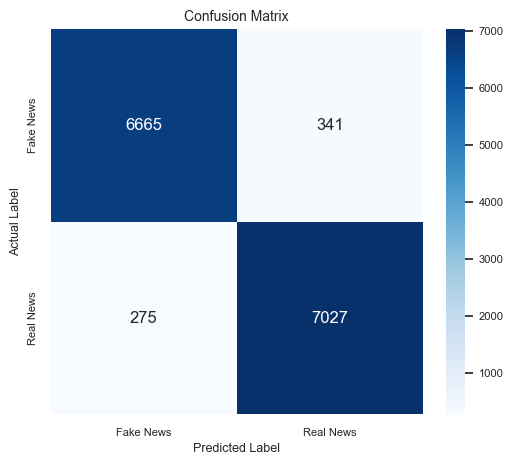

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [79]:
from sklearn.svm import LinearSVC

# Create Linear SVM model
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=100000
    )),
    ("classifier", LinearSVC(random_state=RANDOM_STATE))
])

# Train Linear SVM
svm_pipeline.fit(X_train, y_train)

# Predict on test data
y_pred_svm = svm_pipeline.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("--- Linear SVM Test Metrics ---")
print(f"Accuracy : {svm_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, digits=4))

--- Linear SVM Test Metrics ---
Accuracy : 0.9652

Classification Report:
              precision    recall  f1-score   support

           0     0.9724    0.9560    0.9642      7006
           1     0.9585    0.9740    0.9662      7302

    accuracy                         0.9652     14308
   macro avg     0.9655    0.9650    0.9652     14308
weighted avg     0.9653    0.9652    0.9652     14308



**6. Build predictive system**

In [75]:
def predict_news(title, text):
    combined = clean_text(f"{title} {text}")
    prediction = model_pipeline.predict([combined])

    if prediction[0] == 1:
        return "Real News 🟢"
    else:
        return "Fake News 🔴"

In [76]:
# Example prediction
example_title = "Breaking: Government announces new economic policy"
example_text = "The finance minister introduced a new policy today after discussions in parliament..."
prediction = predict_news(example_title, example_text)
print(prediction)

Real News 🟢


In [77]:
# Example prediction
test_news = [
    {
        "title": "Scientists announce major breakthrough in renewable energy",
        "text": "Researchers have developed a new technology that could improve the efficiency of renewable energy systems."
    },
    {
        "title": "Government announces new education policy",
        "text": "Officials announced changes to the national education system following discussions with education experts."
    },
    {
        "title": "Celebrity claims drinking a special juice makes people immortal",
        "text": "A celebrity posted online claiming that a secret juice can make humans live forever without providing scientific evidence."
    },
    {
        "title": "Scientists discover that humans can breathe underwater naturally",
        "text": "A social media post claims that scientists have discovered humans can breathe underwater without any equipment."
    },
    {
        "title": "Researchers publish study on climate change",
        "text": "Researchers published findings from a new study examining changes in global temperatures and their environmental effects."
    }
]

for i, news in enumerate(test_news, 1):
    prediction = predict_news(news["title"], news["text"])
    
    print(f"News {i}")
    print(f"Title: {news['title']}")
    print(f"Prediction: {prediction}")
    print("-" * 60)

News 1
Title: Scientists announce major breakthrough in renewable energy
Prediction: Real News 🟢
------------------------------------------------------------
News 2
Title: Government announces new education policy
Prediction: Real News 🟢
------------------------------------------------------------
News 3
Title: Celebrity claims drinking a special juice makes people immortal
Prediction: Real News 🟢
------------------------------------------------------------
News 4
Title: Scientists discover that humans can breathe underwater naturally
Prediction: Real News 🟢
------------------------------------------------------------
News 5
Title: Researchers publish study on climate change
Prediction: Real News 🟢
------------------------------------------------------------


What Next?
- Try cross validation
- model selection
- hyperparam tuning

## Conclusion

This project developed a machine learning-based Fake News Detection system using Natural Language Processing (NLP).

The WELFake dataset containing 72,134 news articles was used for training and evaluation. The news text was cleaned and converted into numerical features using TF-IDF.

Two machine learning models were evaluated:

- Logistic Regression — 95.69% test accuracy
- Linear SVM — 96.52% test accuracy

Linear SVM achieved the highest test accuracy among the two models. Logistic Regression provides probability estimates that can be used to display prediction confidence for individual news articles.

The model will be integrated into a Streamlit web application where users can enter a news title and article text and receive a Fake/Real prediction along with prediction confidence and overall model performance metrics.

In [80]:
import joblib

print("joblib is installed and ready!")

joblib is installed and ready!


In [81]:
import joblib
import os

# Create the Model folder if it doesn't exist
os.makedirs("../Model", exist_ok=True)

# Save the trained Logistic Regression pipeline
model_path = "../Model/fake_news_model.pkl"
joblib.dump(model_pipeline, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: ../Model/fake_news_model.pkl


In [82]:
import joblib

# Load the saved model
loaded_model = joblib.load("../Model/fake_news_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [83]:
test_title = "Government announces new economic policy"
test_text = "The government announced a new economic policy after discussions with economic experts."

combined_text = clean_text(f"{test_title} {test_text}")

prediction = loaded_model.predict([combined_text])[0]
probabilities = loaded_model.predict_proba([combined_text])[0]

if prediction == 1:
    result = "Real News 🟢"
    confidence = probabilities[1] * 100
else:
    result = "Fake News 🔴"
    confidence = probabilities[0] * 100

print("Prediction:", result)
print(f"Confidence: {confidence:.2f}%")

Prediction: Real News 🟢
Confidence: 79.87%
